# Uniform and Fréchet parameterizations

A recovered edge map specifies a route in the target graph and when it reaches each point along that route. We compare two ways to assign traversal times for two different pairs of graphs. Uniform timing divides the source edge equally among the route pieces. Fréchet timing chooses traversal times to reduce the height error for the fixed route.

For each graph pair, we recover the maps once and keep their vertex images and routes fixed. We then compare the two height errors, the distance distortion $D$, and their maximum $\mathrm{FD}$. The plots show the forward map, and the scores use both directions.

In [1]:
import sys
from pathlib import Path
from time import perf_counter

import matplotlib.pyplot as plt
from cereeberus import Interleave
from cereeberus.data import ex_mappergraphs as ex
from pulp import PULP_CBC_CMD

if Path.cwd().name == "experiments":
    sys.path.insert(0, str(Path.cwd().parent))

from core.distortion import functional_distortion
from core.fd_map_build import maps_from_interleave
from core.functionaldistortiongraph import FunctionalDistortionGraph
from visualize.fd_metromaps import default_layout, draw_fd_maps


def report(label, F, G, Phi, Psi, preprocessing, construction):
    start = perf_counter()
    result = functional_distortion(F, G, Phi, Psi)
    evaluation = perf_counter() - start
    total = preprocessing + construction + evaluation
    print(
        f"{label} — Elapsed time: total {total:.3f} s "
        f"(preprocessing: {preprocessing:.3f} s, FD map construction: {construction:.3f} s, "
        f"distortion computation: {evaluation:.3f} s)"
    )
    print(
        f"Height Φ = {result['height_Phi_units']} | Height Ψ = {result['height_Psi_units']} | "
        f"D = {result['D_units']} | FD = {result['FD_units']}"
    )
    return result["FD_units"]


In [2]:
def uniform_map(mapping):
    routes = {edge: [piece[3] for piece in pieces[:-1]]
              for edge, pieces in mapping["segments"].items()}
    return mapping["source"].map_to(mapping["target"], mapping["vertex_image"], routes)


def compare_timing(label, make_pair):
    start = perf_counter()
    F, G = make_pair()
    interleaving = Interleave(F, G)
    solver = PULP_CBC_CMD(msg=False, threads=1, options=["randomSeed 1", "randomCbcSeed 1"])
    interleaving.fit(pulp_solver=solver)
    preprocessing = perf_counter() - start

    start = perf_counter()
    maps = maps_from_interleave(interleaving, seed=0)
    construction = perf_counter() - start
    F, G = maps["F"], maps["G"]
    Phi, Psi = maps["Phi"], maps["Psi"]

    start = perf_counter()
    uniform_phi, uniform_psi = uniform_map(Phi), uniform_map(Psi)
    retiming = perf_counter() - start

    report(f"{label}, uniform", F, G, uniform_phi, uniform_psi,
           preprocessing, construction + retiming)
    report(f"{label}, Fréchet", F, G, Phi, Psi, preprocessing, construction)
    return (uniform_phi, uniform_psi), (Phi, Psi)


Both runs share the same interleaving fit and route recovery. The uniform construction time also includes rebuilding the maps with equal traversal times.

Scores are in grid units and are rounded to three decimal places. The saved runs use ceREEBerus 0.2.0, single-threaded CBC, and `PYTHONHASHSEED=0`.

## Y and inverted Y

In [3]:
def y_pair():
    F = FunctionalDistortionGraph.from_edges(
        {"f0": 0, "f1": 1, "f2": 2, "j": 3, "L4": 4, "L5": 5, "R4": 4},
        [("f0", "f1"), ("f1", "f2"), ("f2", "j"), ("j", "L4"), ("L4", "L5"), ("j", "R4")],
    )
    G = FunctionalDistortionGraph.from_edges(
        {"g5": 5, "g4": 4, "g3": 3, "q": 2, "b1": 1, "b0": 0, "c1": 1},
        [("g5", "g4"), ("g4", "g3"), ("g3", "q"), ("q", "b1"), ("b1", "b0"), ("q", "c1")],
    )
    return F.mapper, G.mapper



uniform, frechet = compare_timing("Y → Λ", y_pair)


Y → Λ, uniform — Elapsed time: total 0.469 s (preprocessing: 0.421 s, FD map construction: 0.013 s, distortion computation: 0.034 s)
Height Φ = 1.5 | Height Ψ = 1.5 | D = 1.0 | FD = 1.5
Y → Λ, Fréchet — Elapsed time: total 0.471 s (preprocessing: 0.421 s, FD map construction: 0.013 s, distortion computation: 0.037 s)
Height Φ = 1.0 | Height Ψ = 1.0 | D = 1.0 | FD = 1.0


Uniform
Fréchet


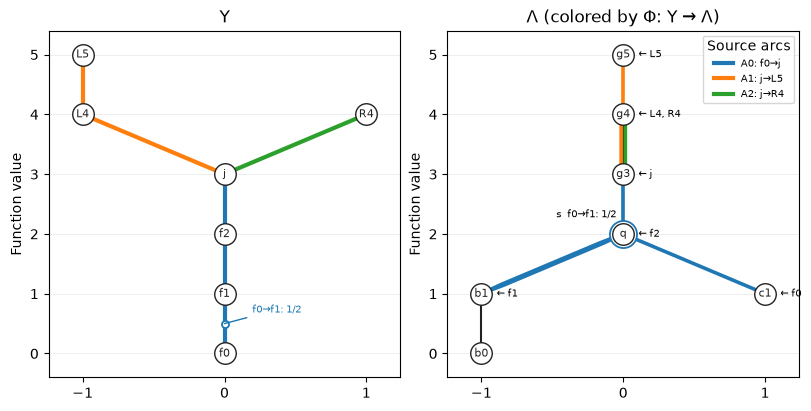

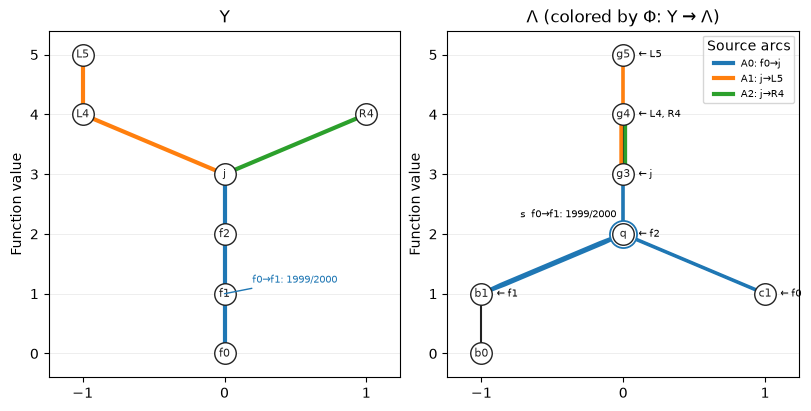

In [4]:
x_f = {"L4": -1, "L5": -1, "R4": 1}
x_g = {"b0": -1, "b1": -1, "c1": 1}
Phi, _ = frechet
pos_f = {v: (x_f.get(v, 0), h) for v, h in Phi["source"].f.items()}
pos_g = {v: (x_g.get(v, 0), h) for v, h in Phi["target"].f.items()}

for name, (Phi, Psi) in [("Uniform", uniform), ("Fréchet", frechet)]:
    print(name)
    draw_fd_maps(Phi, Psi, posF=pos_f, posG=pos_g, names=("Y", "Λ"),
                 direction="phi", show_frechet_param=True, figsize=(8, 4))
    plt.show()


The printed scores use both map directions. The plots show the forward map and label its traversal times at the breakpoints.

## ceREEBerus A/B pair

Both plots show the forward map $\Phi\colon A\to B$. We label the breakpoint with the largest change in traversal time. The label $t$ gives its position along the source edge, from $0$ at the lower endpoint to $1$ at the upper endpoint.

A/B, uniform — Elapsed time: total 3.783 s (preprocessing: 2.218 s, FD map construction: 0.343 s, distortion computation: 1.222 s)
Height Φ = 4.5 | Height Ψ = 2.4 | D = 3.5 | FD = 4.5
A/B, Fréchet — Elapsed time: total 3.844 s (preprocessing: 2.218 s, FD map construction: 0.342 s, distortion computation: 1.284 s)
Height Φ = 4.0 | Height Ψ = 2.0 | D = 3.5 | FD = 4.0


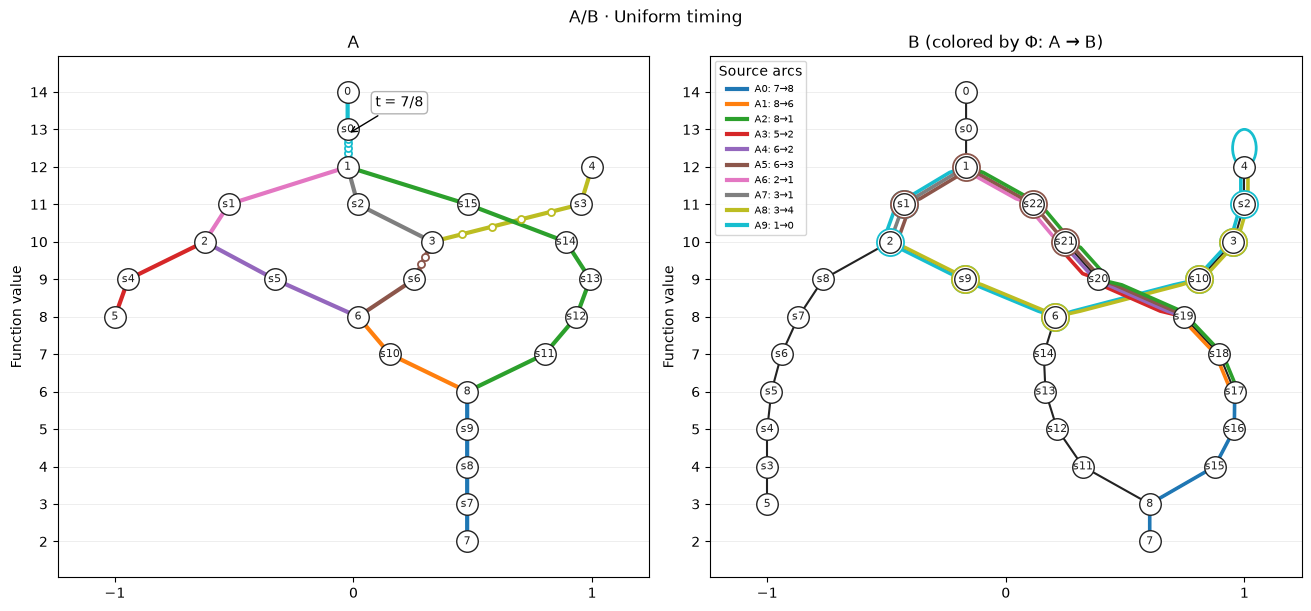

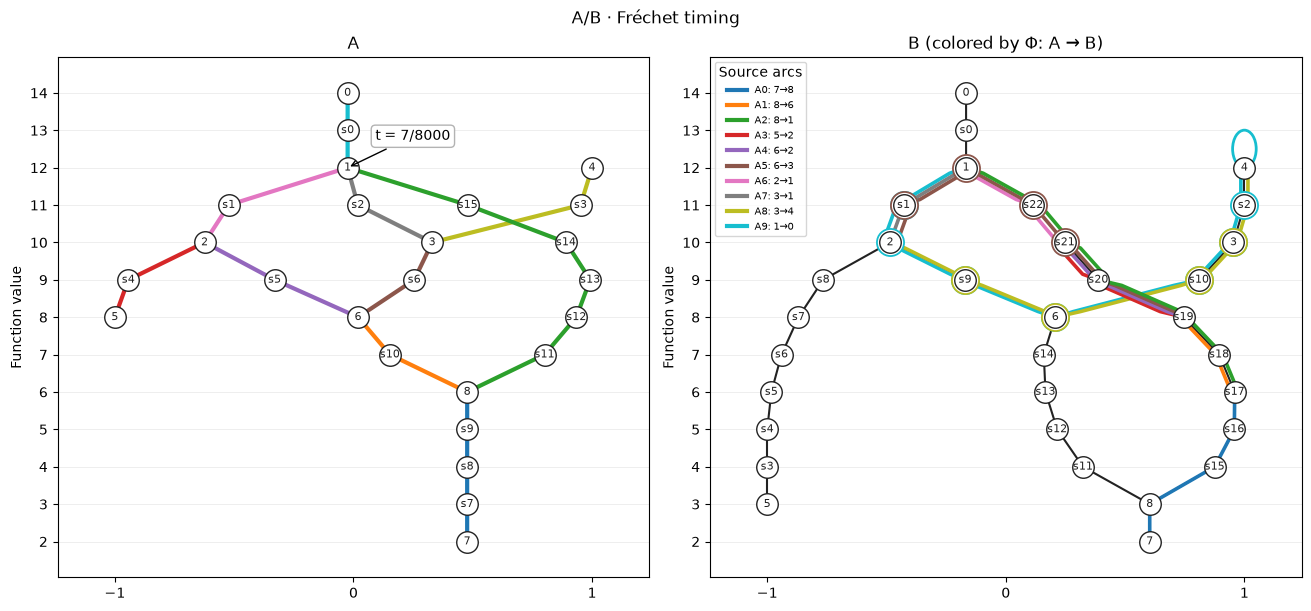

In [5]:
ab_uniform, ab_frechet = compare_timing(
    "A/B", lambda: (ex.interleave_example_A(seed=0), ex.interleave_example_B(seed=0))
)

uniform_phi, _ = ab_uniform
frechet_phi, _ = ab_frechet
changes = []
for edge, pieces in uniform_phi["segments"].items():
    frechet_pieces = frechet_phi["segments"][edge]
    for i in range(1, len(pieces)):
        change = abs(pieces[i][0] - frechet_pieces[i][0])
        changes.append((change, edge, i))

_, edge, breakpoint_index = max(changes, key=lambda item: item[0])
source_layout = default_layout(frechet_phi["source"])
start, end = (source_layout[v] for v in edge)

for name, (Phi, Psi) in [("Uniform", ab_uniform), ("Fréchet", ab_frechet)]:
    fig = draw_fd_maps(Phi, Psi, names=("A", "B"), direction="phi", posF=source_layout,
                       show_vertmaps=False, figsize=(13, 6))
    t = Phi["segments"][edge][breakpoint_index][0]
    point = start + float(t) * (end - start)
    fig.axes[0].annotate(
        f"t = {t}", xy=point, xytext=(20, 20), textcoords="offset points",
        arrowprops={"arrowstyle": "->"}, bbox={"boxstyle": "round", "fc": "white", "ec": "0.7"},
        zorder=10,
    )
    fig.suptitle(f"A/B · {name} timing")
    plt.show()
